In [1]:
import matplotlib.pyplot as plt
import numpy as np
import re
import pandas as pd
from scipy.interpolate import RBFInterpolator
from scipy import optimize
from dolfin import *
import matplotlib as mpl
from scipy.optimize import curve_fit
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
from numpy import inf
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import differential_evolution
from sklearn.model_selection import train_test_split
import dill
from SALib.sample import latin
from SALib.sample import saltelli

In [10]:
def get_n(s):
    match = re.search(r'\d+$', s)
    if match:
        return int(match.group())
    else:
        return None

def loocv(params, x, y, kernel, rescaler):
    ep, smooth = params
    n = len(x)
    err = []

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        try:
            rbf = RBFInterpolator(
                x[mask], y[mask],
                kernel=kernel,
                epsilon=ep,
                smoothing=smooth,
            )
            y_hat = rbf(x[i:i+1])[0]
            if rescaler.inverse_transform(y_hat.reshape(1, -1)) < 0:
                err.append(((y_hat - y[i]) ** 2) * 1e10)
            else:
                err.append((y_hat - y[i]) ** 2)
        except (np.linalg.LinAlgError, ValueError):
            return 1e10

    return np.array(err).reshape(-1)

def error_obj(params, x, y, kernel, rescaler):
    '''
    mean of mean squared error for LOOCV and train/test.
    '''
    loocv_err = loocv(params, x, y, kernel, rescaler)
    test_err = train_test(params, x, y, kernel, rescaler) 
    return np.mean(np.array([np.mean(loocv_err), np.mean(test_err)]))

def train_test(params, x, y, kernel, rescaler):
    ep, smooth = params
    
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)
    
    rbf = RBFInterpolator(x_train, y_train, kernel = kernel, epsilon = ep, smoothing = smooth)
    
    y_hat = rbf(x_test)
    if (rescaler.inverse_transform(y_hat.reshape(1, -1)) < 0).any():
        err = ((y_hat - y_test) ** 2) * 1e10
    else:
        err = (y_hat - y_test) ** 2

    return np.array(err).reshape(-1)

def fit_rbf_param(x, y, rescaler):
    kernels = ['linear', 'gaussian', 'thin_plate_spline', 'multiquadric', 'inverse_multiquadric']
    
    best_overall = None
    
    for kernel in kernels:
        if kernel in {'thin_plate_spline', 'cubic', 'linear', 'quintic'}:
            result = differential_evolution(
                lambda s, X, Y, k, rs: error_obj([1.0, s[0]], X, Y, k, rs),
                bounds = [(1e-5, 25.0)],
                args = (x, y, kernel, rescaler),
                seed = 42,
            )
            score = result.fun
            params = {'kernel': kernel, 'epsilon': 1.0, 'smoothing': result.x[0]}
        else:
            result = differential_evolution(
                error_obj,
                bounds = [(1e-2, 2.0), (1e-5, 25.0)],
                args = (x, y, kernel, rescaler),
                seed = 42,
            )
            score = result.fun
            params = {'kernel': kernel, 'epsilon': result.x[0], 'smoothing': result.x[1]}
    
        print(f"{kernel:>25s} MSE={score:}")
    
        if best_overall is None or score < best_overall['score']:
            best_overall = {'score': score, **params}
    
    print(f"\nBest: {best_overall}")

    return best_overall

In [4]:
headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
PDE_mn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)[['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']]
PDE_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)[['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']]
PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)[['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']]

PDE_ub = PDE_ub.rename(columns={'alpha': 'alpha_ub', 'beta': 'beta_ub', 'vd': 'vd_ub', 'sg': 'sg_ub', 'D': 'D_ub'})
PDE = pd.merge(pd.merge(PDE_mn,PDE_lb,on='sim_name', suffixes=('_mn', '_lb') ),PDE_ub,on='sim_name')
PDE = PDE[(PDE['beta_mn'] > 7 * 1e-4)  & (PDE['beta_lb'] > 7 * 1e-4) * (PDE['beta_ub'] > 7 * 1e-4)].reset_index(drop=True)

PDE_names = PDE['sim_name']

PDE_mn = PDE[['alpha_mn', 'beta_mn', 'vd_mn', 'sg_mn', 'D_mn']].to_numpy()
mn_scaler = MinMaxScaler()
mn_scaler.fit(PDE_mn)
PDE_mn_norm = mn_scaler.transform(PDE_mn)
PDE_lb = PDE[['alpha_lb', 'beta_lb', 'vd_lb', 'sg_lb', 'D_lb']].to_numpy()
lb_scaler = MinMaxScaler()
lb_scaler.fit(PDE_lb)
PDE_lb_norm = lb_scaler.transform(PDE_lb)
PDE_ub = PDE[['alpha_ub', 'beta_ub', 'vd_ub', 'sg_ub', 'D_ub']].to_numpy()
ub_scaler = MinMaxScaler()
ub_scaler.fit(PDE_ub)
PDE_ub_norm = ub_scaler.transform(PDE_ub)

In [5]:
# headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
# PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)['sim_name']
# PDE_mn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# mn_scaler = MinMaxScaler()
# mn_scaler.fit(PDE_mn)
# PDE_mn_norm = mn_scaler.transform(PDE_mn)
# PDE_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# lb_scaler = MinMaxScaler()
# lb_scaler.fit(PDE_lb)
# PDE_lb_norm = lb_scaler.transform(PDE_lb)
# PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# ub_scaler = MinMaxScaler()
# ub_scaler.fit(PDE_ub)
# PDE_ub_norm = ub_scaler.transform(PDE_ub)

In [8]:
inputs = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
input_names = ['chem_species.max_seg_length', 'chem_species.seg_split_length',
               'chem_species.max_seg_radius', 'chem_species.splitting_probability',
               'chem_species.fusion_probability', 'chem_species.max_fusion_separation',
               'cell_force.fungi_boundary_width'] 
ABM_256_inputs = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/256_inputs/256_inputs.csv')
ABM_sample = np.zeros((len(PDE_names), 7))
j = 0
sim_names = PDE_names.to_list()
for sim in sim_names:
    n = get_n(sim)
    sim_row = ABM_256_inputs.iloc[n]
    i = 0
    for name in input_names:
        ABM_sample[j, i] = sim_row[name]
        i += 1
    j += 1

# [[17.5e-4, 52.5e-4], [2.5e-4, 7.5e-4], [1.25e-4, 3.75e-4], [0.1, 0.3], [0.005, 0.015], [3.0e-4, 9.0e-4], [0.5e-4, 1.5e-4]]
ABM_scaler = MinMaxScaler()
# ABM_toscale = np.append(ABM_sample, [[16.5e-4, 16.5e-4 - 8.5e-4, 0.25e-4, 0.05, 0.004, 2.0e-4, 0.4e-4]], axis=0) # adding smallest and largest possible values
# ABM_toscale = np.append(ABM_toscale, [[53.5e-4, 53.5e-4 - 1.5e-4, 4.75e-4, 0.4, 0.025, 10.0e-4, 1.5e-4]], axis=0)
ABM_scaler.fit(ABM_sample)
ABM_norm = ABM_scaler.transform(ABM_sample)

interpolating alpha mean.
                   linear MSE=0.02630988149287651
                 gaussian MSE=0.02188691005689645
        thin_plate_spline MSE=0.021865958482298872
             multiquadric MSE=0.021895742338872856
     inverse_multiquadric MSE=0.02188731508481557

Best: {'score': np.float64(0.021865958482298872), 'kernel': 'thin_plate_spline', 'epsilon': 1.0, 'smoothing': np.float64(1.145715100127914)}
interpolating beta mean.
                   linear MSE=0.025467164145459874
                 gaussian MSE=0.02248871366828055
        thin_plate_spline MSE=0.021097290792045382
             multiquadric MSE=0.022331718185074585
     inverse_multiquadric MSE=0.022584219338781197

Best: {'score': np.float64(0.021097290792045382), 'kernel': 'thin_plate_spline', 'epsilon': 1.0, 'smoothing': np.float64(0.39717773625041985)}
interpolating vd mean.
                   linear MSE=0.02365495874686336
                 gaussian MSE=0.02355798514446323
        thin_plate_spline MSE=0.02

NameError: name 'err_mn' is not defined

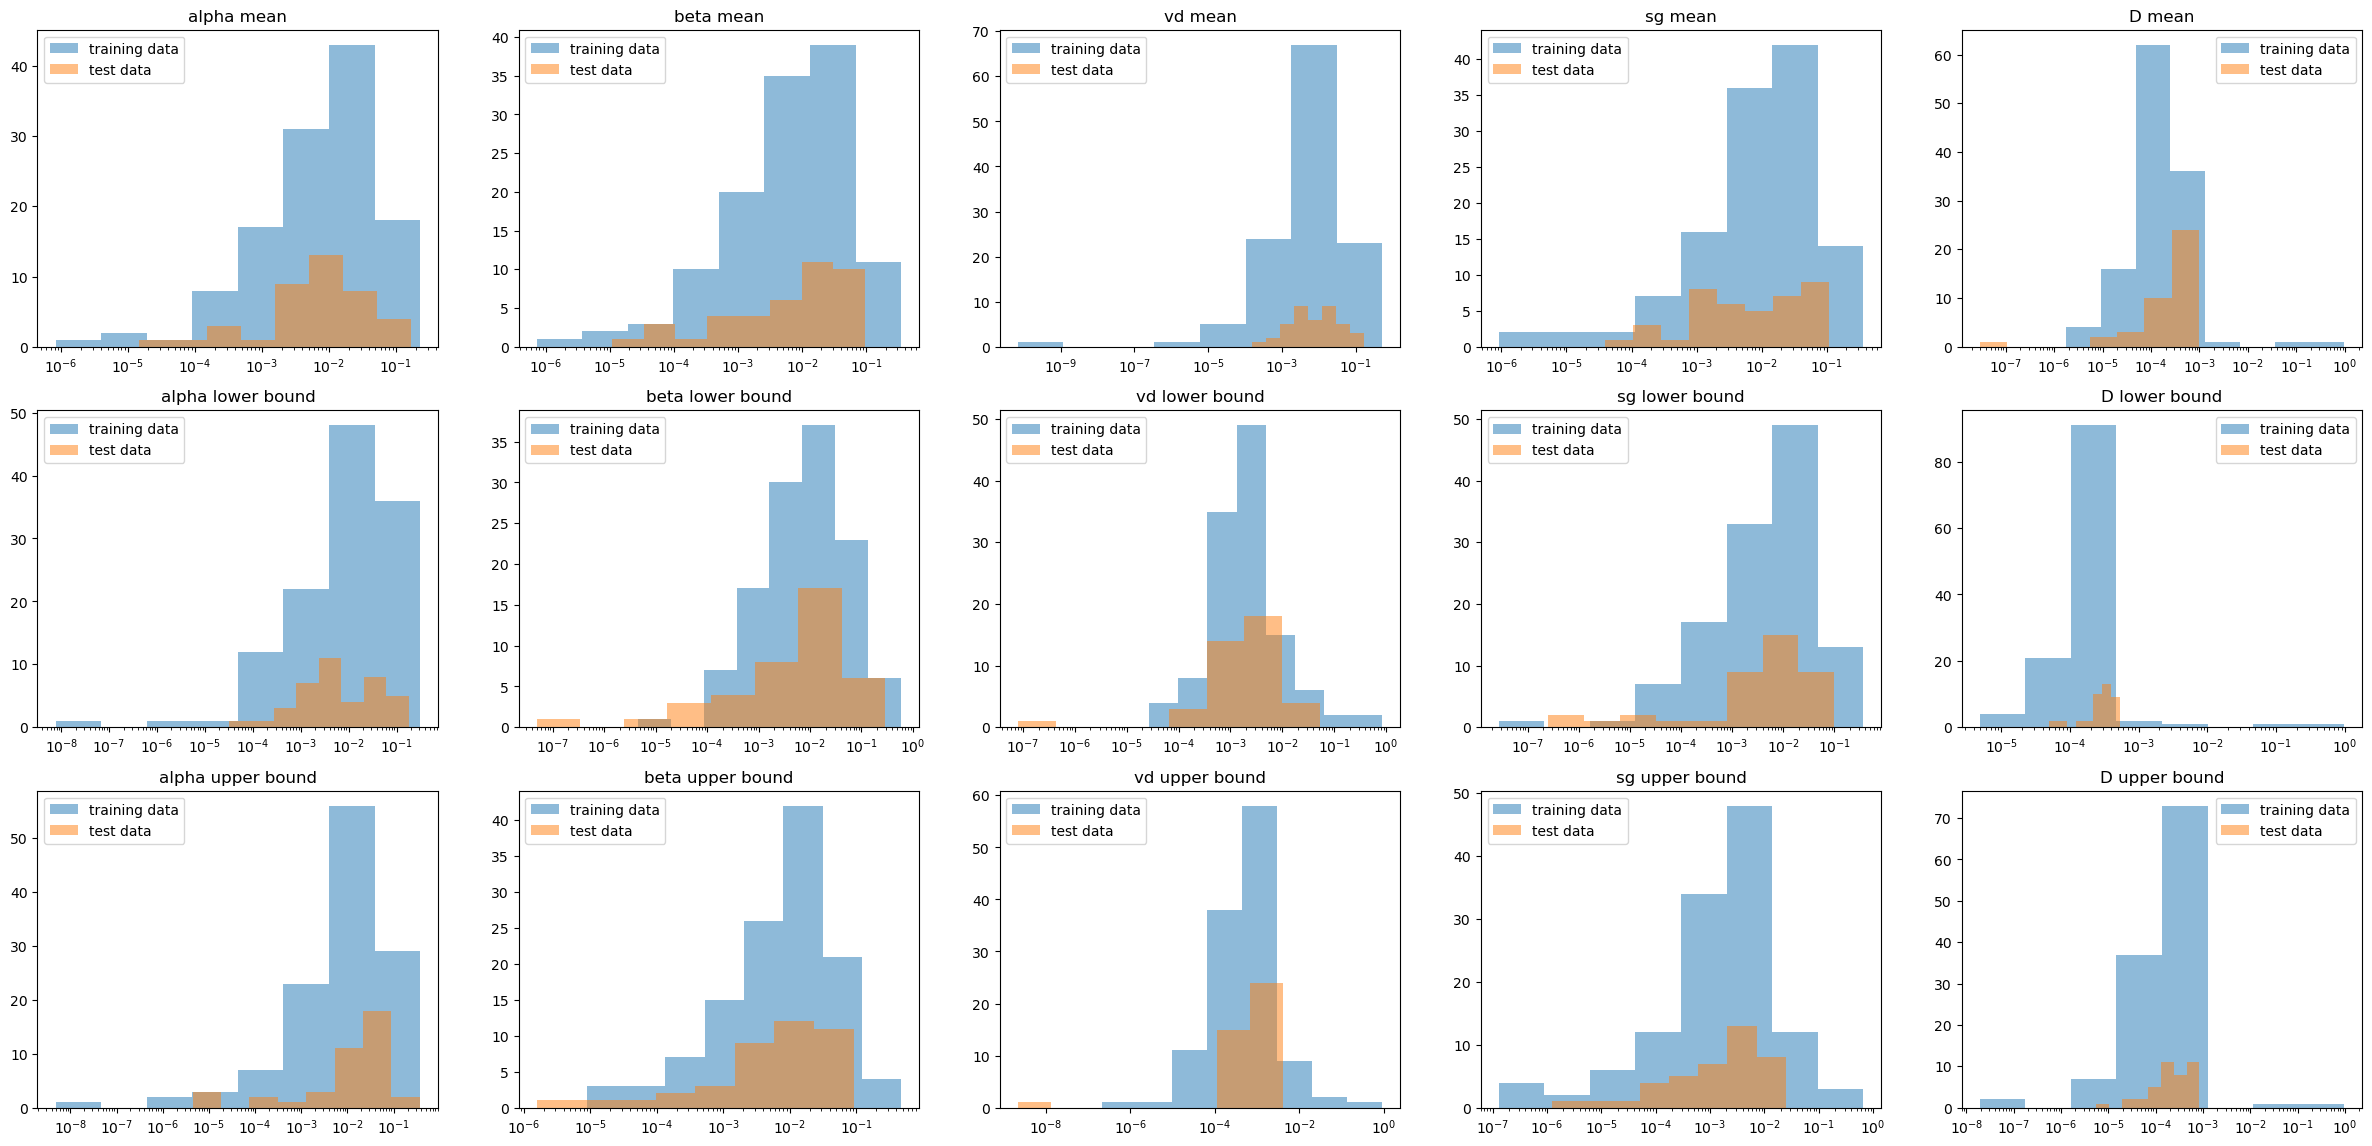

In [11]:
fig, ax = plt.subplots(3, 5, figsize=(30, 14))
PDE_par = ['alpha', 'beta', 'vd', 'sg', 'D']
bns = 8
ts = 0.33
a = 0.5
err_m = []
err_lb = []
err_ub = []

# median/mean
for i in range(5):
    print('interpolating ' + str(PDE_par[i]) + ' mean.')
    scaler = MinMaxScaler()
    scaler.fit(PDE_mn[:, i].reshape(-1,1))
    PDE_norm = scaler.transform(PDE_mn[:, i].reshape(-1,1))
    rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
    kern = rbf_fit['kernel']
    smooth = rbf_fit['smoothing']
    ep = rbf_fit['epsilon']
    train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    err_mask = train_err > 10
    if len(ABM_sample[err_mask]) > 0:
        err_mn.append(ABM_sample[err_mask])
    
    logbins = np.geomspace(min(train_err), max(train_err), bns+1)
    ax[0,i].hist(train_err, label = 'training data', bins=logbins, alpha=a)
    logbins = np.geomspace(min(test_err), max(test_err), bns+1)
    ax[0,i].hist(test_err, label = 'test data', bins=logbins, alpha=a)
    ax[0,i].set_title(PDE_par[i] + ' mean')
    ax[0,i].set_xscale('log')
    ax[0,i].legend()
          
    rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, epsilon = ep, smoothing = smooth)
    with open(PDE_par[i] + '_mn_drop_rbf' + '.pkl', 'wb') as f:
        dill.dump(rbfi, f)
    
# lower bound
for i in range(5):
    print('interpolating ' + str(PDE_par[i]) + ' lower.')
    scaler = MinMaxScaler()
    scaler.fit(PDE_lb[:, i].reshape(-1,1))
    PDE_norm = scaler.transform(PDE_lb[:, i].reshape(-1,1))
    rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
    kern = rbf_fit['kernel']
    smooth = rbf_fit['smoothing']
    ep = rbf_fit['epsilon']
    train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    err_mask = train_err > 10
    if len(ABM_sample[err_mask]) > 0:
        err_lb.append(ABM_sample[err_mask])
    
    logbins = np.geomspace(min(train_err), max(train_err), bns+1)
    ax[1,i].hist(train_err, label = 'training data', bins=logbins, alpha=a)
    logbins = np.geomspace(min(test_err), max(test_err), bns+1)
    ax[1,i].hist(test_err, label = 'test data', bins=logbins, alpha=a)
    ax[1,i].set_title(PDE_par[i] + ' lower bound')
    ax[1,i].set_xscale('log')
    ax[1,i].legend()

    rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, smoothing = smooth, epsilon = ep)
    with open(PDE_par[i] + '_lb_drop_rbf' + '.pkl', 'wb') as f:
        dill.dump(rbfi, f)
        
# upper bound
for i in range(5):
    print('interpolating ' + str(PDE_par[i]) + ' upper.')
    scaler = MinMaxScaler()
    scaler.fit(PDE_ub[:, i].reshape(-1,1))
    PDE_norm = scaler.transform(PDE_ub[:, i].reshape(-1,1))
    rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
    kern = rbf_fit['kernel']
    smooth = rbf_fit['smoothing']
    ep = rbf_fit['epsilon']
    train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    err_mask = train_err > 10
    if len(ABM_sample[err_mask]) > 0:
        err_ub.append(ABM_sample[err_mask])
    
    logbins = np.geomspace(min(train_err), max(train_err), bns+1)
    ax[2,i].hist(train_err, label = 'training data', bins=logbins, alpha=a)
    logbins = np.geomspace(min(test_err), max(test_err), bns+1)
    ax[2,i].hist(test_err, label = 'test data', bins=logbins, alpha=a)
    ax[2,i].set_title(PDE_par[i] + ' upper bound')
    ax[2,i].set_xscale('log')
    ax[2,i].legend()

    rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, smoothing = smooth, epsilon = ep)
    with open(PDE_par[i] + '_ub_drop_rbf' + '.pkl', 'wb') as f:
        dill.dump(rbfi, f)
        
err_mn = np.concatenate(err_mn, axis=0)
err_lb = np.concatenate(err_lb, axis=0)
err_ub = np.concatenate(err_ub, axis=0)